# Lumped JPAs, capacitively and inductively coupled (twpa-sim `jpa` / `jpa_inductive`), rebuilt in the Quantcore PDK

**What it is.** The simplest Josephson parametric amplifier: one junction shunted by a capacitor, a lumped LC mode
whose inductance is the junction's L_J(I). Pumped through the signal port near resonance, the junction's Kerr
nonlinearity mixes pump, signal and idler (four-wave mixing) and amplifies in reflection (Eichler & Wallraff,
EPJ Quantum Technology 1, 2 (2014)). Two ways to couple the mode to the 50 Ω line: a series capacitor, or a shared
(pickup) inductance.

**Source.** twpa-sim (S. Mandal, MIT), `src/twpa/layout/generate.py`, families `jpa` and `jpa` with
`inductive_coupler=true` (`examples/layout/jpa.json`, `jpa_inductive.json`), on its *illustrative* two-metal
overlap process (`jj_overlap_illustrative.json`: J_c 5 µA/µm², C_J 60 fF/µm², MIM 1 fF/µm²): a 2 × 2 µm junction
(I_c 20 µA, C_J 240 fF) shunted by a 12 × 12 µm MIM capacitor (144 fF); the inductive variant adds an M1 pickup loop
(gap 8, height 10, length 40 µm). Cloned read-only into `build/external/twpa-sim` (rev 05abc83), never run.

**This is a Quantcore-PDK rebuild**: the topology (junction ∥ shunt C to ground, capacitive or inductive coupling to
a one-port line) on our process.

| | twpa-sim source | Quantcore rebuild (why) |
|---|---|---|
| junction | 2 × 2 µm overlap JJ, I_c 20 µA, C_J 240 fF | the **largest PDK trilayer junction** (2 × 2 µm fingers): I_c 0.65 µA, L_J 0.51 nH, C_J 200 fF (J_c is the PDK's qubit rule); flagged `pdk_rn` |
| shunt C | 12 × 12 µm MIM, 144 fF (no MIM on our process) | a planar interdigital capacitor island–ground (`LumpedJpa`), ≈ 0.9 pF so that f0 ≈ 7 GHz |
| f0 | ≈ 63 GHz (illustrative values) | ≈ 6–7 GHz (a usable JPA band with the PDK junction) |
| capacitive coupling | external (twpa-sim: "coupling and bias circuitry is external") | KQC `FingerCapacitorSquare` snapped to the island lead |
| inductive coupling | M1 pickup loop, mutual M (needs EM extraction) | a **tapped inductance**: the junction's ground side lands on a strip shared with the signal line (galvanic, its L is analytic: geometry + Nb kinetic inductance) |
| chip | none (device cells) | 7.5 × 7.5 mm PDK die, two `BondPad`s 100 µm from the edge |

## 1 · Setup and the PDK

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_values, c_fF
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import LumpedJpa, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
RUN_FEM = False
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

In [3]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LJ, CJ, _ = drawn_junction_values("Quantcore Junction", BIG_JJ)
JUNCTION = {"Lj_nH": LJ, "Cj_fF": CJ}
SRC = {"Ic_uA": 20.0, "Cj_fF": 240.0, "C_mim_fF": 144.0}         # twpa-sim illustrative process, 2 × 2 µm
lj_src = amp.lj_from_ic(SRC["Ic_uA"] * 1e-6)
f_src = 1 / (2 * np.pi * np.sqrt(lj_src * (SRC["Cj_fF"] + SRC["C_mim_fF"]) * 1e-15)) / 1e9
show_md(table_md(["junction", "I_c (µA)", "L_J (nH)", "C_J (fF)", "R_n (kΩ)"], [
    ["drawn: trilayer 2.0 × 2.0 µm (PDK max)", amp.ic_from_lj(LJ * 1e-9) * 1e6, LJ, CJ, rn_from_lj(LJ) / 1e3],
    ["twpa-sim illustrative 2 × 2 µm", SRC["Ic_uA"], lj_src * 1e9, SRC["Cj_fF"], rn_from_lj(lj_src * 1e9) / 1e3]])
    + f"\n\ntwpa-sim's own LC: f0 = 1/2π√(L_J (C_J + C_MIM)) ≈ {f_src:.0f} GHz (illustrative, not a design target).")

| junction | I_c (µA) | L_J (nH) | C_J (fF) | R_n (kΩ) |
|---|---|---|---|---|
| drawn: trilayer 2.0 × 2.0 µm (PDK max) | 0.6516 | 0.5051 | 200 | 3.375 |
| twpa-sim illustrative 2 × 2 µm | 20 | 0.01646 | 240 | 0.11 |

twpa-sim's own LC: f0 = 1/2π√(L_J (C_J + C_MIM)) ≈ 63 GHz (illustrative, not a design target).

## 2 · The die and frame

In [4]:
W = H = 7500
YC, YL = 4600, 2900                              # capacitive JPA (north), inductive JPA (south)
d = Designer("twpa_sim_jpa", box=(0, 0, W, H), chip={"name_chip": "LJPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
One `BondPad` per JPA (each JPA is a one-port amplifier used in reflection): the capacitive one fed from the west
edge, the inductive one from the east edge, so the content sits centred; `edge="auto"` puts each pad's outer
etch 100 µm from the die edge.

In [5]:
with d.batch():
    d.add("P_C", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_L", "BondPad", at=(7100, YL), rot=90, edge="auto")

## 4 · Components
`LumpedJpa`: an island (20 µm spine, `shunt_fingers` fingers per side, 150 µm long, 4 µm wide, 4 µm gaps) in its
own pocket; the ground fingers hang from the pocket walls, so the island–ground IDC is the shunt C. The trilayer
junction bridges a 16 µm gap at the junction end (window 32 × 16 µm; its fingers land on a 2 µm landing head).
* `JC` (capacitive): the island's lead is the port `signal`; `CC` (KQC `FingerCapacitorSquare`, 12 fingers × 80 µm)
  is snapped to it — the coupling capacitor. The junction is at the far end, to the pocket wall.
* `JL` (inductive): the lead ends on a tap pad tied to the pocket floor by a 152 µm × `tap_width` strip; the
  junction joins the tap pad and the island. The strip is the inductance the line and the JPA loop share.

In [6]:
SHUNT = dict(shunt_fingers=30, finger_length=150, finger_width=4, finger_gap=4)
with d.batch():
    cc = d.add("CC", "FingerCapacitorSquare", at=(3100, YC), finger_number=12, finger_length=80, finger_width=5,
               finger_gap=3)
    jc = d.add("JC", "LumpedJpa", snap="signal", to="CC.b", junction=JUNCTION, junction_params=BIG_JJ, **SHUNT)
    jl = d.add("JL", "LumpedJpa", at=(4400, YL), rot=180, coupling="inductive", tap_width=8, junction=JUNCTION,
               junction_params=BIG_JJ, **SHUNT)
show_md(table_md(["JPA", "C_shunt (fF, analytic)", "L_tap (nH)", "of which kinetic (pH)"], [
    ["JC", LumpedJpa.qcc_values(jc.spec["params"])["C_shunt_fF"], None, None],
    ["JL", LumpedJpa.qcc_values(jl.spec["params"])["C_shunt_fF"],
     LumpedJpa.qcc_values(jl.spec["params"])["L_tap_nH"], 1e3 * LumpedJpa.qcc_values(jl.spec["params"])["L_tap_k_nH"]]]))

| JPA | C_shunt (fF, analytic) | L_tap (nH) | of which kinetic (pH) |
|---|---|---|---|
| JC | 883.8 | – | – |
| JL | 883.8 | 0.1276 | 2.2 |

## 5 · Routes
Plain 50 Ω feeds from each pad: to the capacitor (`L_C`) and to the inductive JPA's tap (`L_L`).

In [7]:
with d.batch():
    d.route("L_C", "P_C.a", "CC.a")
    d.route("L_L", "P_L.a", "JL.signal")
d.sim_group("jpa_c", ["CC", "JC"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("jpa_l", ["JL"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "twpa_sim_jpa.json")
print(d, "→", DESIGN)

<Designer twpa_sim_jpa: 5 instances, 2 routes, live=False> → examples\designs\amplifiers\twpa_sim_jpa.json


## 6 · DRC
`dangling_port` warnings on `squid_a` / `squid_b` are the junction ends (FEM ports); `pdk_rn` flags each junction's
R_n ≈ 3.4 kΩ (qubit window 40–50 kΩ) — an amplifier junction, kept as designed.

In [8]:
print(d.drc())
show_md(pdk_report(d))

warning dangling_port JC.squid_a is not connected (no route or snap)
warning dangling_port JC.squid_b is not connected (no route or snap)
warning dangling_port JL.squid_a is not connected (no route or snap)
warning dangling_port JL.squid_b is not connected (no route or snap)
design  pdk_rn        JC: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH)
design  pdk_rn        JL: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 2 |
| PDK design warnings | 2 (pdk_rn × 2) |
| pdk_rn | JC: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH) |
| pdk_rn | JL: junction R_n 3.4 kΩ is outside the PDK window 40–50 kΩ (L_J 0.50508 nH) |

## 7 · Netlist and LOM
`JC`: island node with C_shunt and the JJ to ground; `CC`'s π network to the pad node (50 Ω). `JL`: island node
(C_shunt), the JJ island–tap, the tap node with L_tap (strip, Grover + Nb kinetic inductance) and a small pad C to
ground; the pad's 50 Ω sits on the tap — the tapped-inductor coupling.

In [9]:
lb = d.lom()
show_netlist(lb)

**5 nodes · 11 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `CC.a` | `P_C.pad`, `CC.a` |
| `JL.tap` | `P_L.pad`, `JL.tap` |
| `JC` | `CC.b`, `JC.island` |
| `JL` | `JL.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_C` | R | `CC.a` – `gnd` | 50 Ω |
| `Port_P_L` | R | `JL.tap` – `gnd` | 50 Ω |
| `C_CC` | C | `CC.a` – `JC` | 59 fF |
| `C_CC_a` | C | `CC.a` – `gnd` | 12 fF |
| `C_CC_b` | C | `JC` – `gnd` | 12 fF |
| `C_JC` | C | `JC` – `gnd` | 884 fF |
| `J_JC` | JJ | `JC` – `gnd` | Lj 0.505 nH, Cj 200 fF |
| `C_JL` | C | `JL` – `gnd` | 884 fF |
| `Ltap_JL` | L | `JL.tap` – `gnd` | 0.128 nH |
| `Ctap_JL` | C | `JL.tap` – `gnd` | 9 fF |
| `J_JL` | JJ | `JL` – `JL.tap` | Lj 0.505 nH, Cj 200 fF |

**Unconnected ports:** none

**Builder notes:**

- JC: lumped JPA, C_shunt ≈ 884 fF (analytic IDC)
- JL: lumped JPA, C_shunt ≈ 884 fF (analytic IDC)

## 8 · LOM simulation: resonance, Q and Kerr
QuCat normal modes (first order: f, κ through the 50 Ω pad, anharmonicity = self-Kerr K per photon).

In [10]:
groups = {"capacitive": ["P_C", "L_C", "CC", "JC"], "inductive": ["P_L", "L_L", "JL"]}
res = simulate_groups(d, groups, max_modes=1)
for g, r in res.items():
    display(Markdown(f"**{g}**\n\n" + modes_md(r)))
MODE = {g: r.modes[0] for g, r in res.items()}
show_md(table_md(["JPA", "f0 (GHz)", "κ/2π (MHz)", "Q_ext", "|K|/2π (MHz)"],
                 [[g, m.f_GHz, m.kappa_MHz, m.f_GHz * 1e3 / m.kappa_MHz, abs(m.anharmonicity_MHz)]
                  for g, m in MODE.items()]))

**capacitive**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| JC | qubit | 6.5923 | 40.3 | 16.8 | J_JC 1.00 |

**inductive**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| JL | qubit | 6.8018 | 95.8 | 17.9 | J_JL 1.00 |

| JPA | f0 (GHz) | κ/2π (MHz) | Q_ext | |K|/2π (MHz) |
|---|---|---|---|---|
| capacitive | 6.592 | 40.35 | 163.4 | 16.82 |
| inductive | 6.802 | 95.83 | 70.97 | 17.87 |

**Gain vs pump** (Kerr / current-pumped paramp, `analysis.amplifiers`): the pump at Δ = ω_p − ω0 below resonance
(K < 0) holds n photons, n[(κ/2)² + (Δ − K n)²] = κ Φ_in; the linearised response has δ0 = ω0 − ω_p + 2Kn and
g = K n. Δ = −0.9·√3 κ/2 stays just inside the monostable regime (bistability starts at |Δ| = √3 κ/2): the gain
rises with the pump power to a maximum, then falls as the pump detunes the mode past the signal.

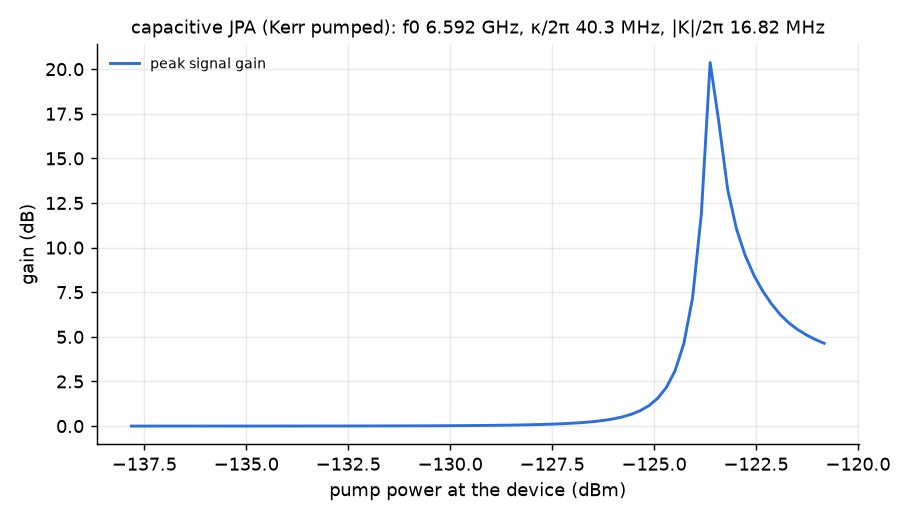

Peak gain 20.4 dB at -123.6 dBm (single-mode Kerr model, undepleted pump).

In [11]:
m = MODE["capacitive"]
kappa, kerr = 2 * np.pi * m.kappa_MHz * 1e6, -2 * np.pi * abs(m.anharmonicity_MHz) * 1e6  # junction: K < 0
delta_p = -0.9 * np.sqrt(3) * kappa / 2
flux_c = (kappa / 2) ** 3 / abs(kerr) / kappa      # photon flux scale where K n ~ κ/2
fluxes = np.geomspace(0.05, 2.5, 80) * flux_c
peak = []
for fl in fluxes:
    n = amp.kerr_pump_photons(delta_p, kerr, kappa, 0.0, fl)[0][0]
    peak.append(float(amp.db(amp.kerr_gain(np.linspace(-2, 2, 801) * kappa, delta_p, kerr, kappa, 0.0, n)).max()))
p_dbm = 10 * np.log10(fluxes * amp.H_PLANCK * (m.f_GHz * 1e9 + delta_p / 2 / np.pi) / 1e-3)
plot(OUT / "twpa_sim_jpa_gain.png", [(p_dbm, peak, "peak signal gain")], "pump power at the device (dBm)",
     "gain (dB)", f"capacitive JPA (Kerr pumped): f0 {m.f_GHz:.3f} GHz, κ/2π {m.kappa_MHz:.1f} MHz, "
     f"|K|/2π {abs(m.anharmonicity_MHz):.2f} MHz")
i = int(np.argmax(peak))
show_md(f"Peak gain {peak[i]:.1f} dB at {p_dbm[i]:.1f} dBm (single-mode Kerr model, undepleted pump).")

## 9 · FEM: send the jobs
A Q3D C-matrix job of each JPA (island, coupling capacitor, tap pad) and an eigenmode job with the junction as a
lumped inductor at `squid_a` / `squid_b`. Export only (`RUN_FEM = False`).

In [12]:
jobs = export_sims(DESIGN, ["jpa_c", "jpa_l"])
jobs_eig = export_sims(DESIGN, ["jpa_c", "jpa_l"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    for job, _ in list(jobs.values()) + list(jobs_eig.values()):
        solve_job(job)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| jpa_c | `build/jobs/twpa_sim_jpa_jpa_c_q3d_cmatrix` | 1 · junction · `JC.junction`<br>2 · edge · `L_C` | `JC.island`, `L_C` |
| jpa_l | `build/jobs/twpa_sim_jpa_jpa_l_q3d_cmatrix` | 1 · junction · `JL.junction`<br>2 · edge · `L_L` | `JL.island`, `JL.tap` |
| jpa_c | `build/jobs/twpa_sim_jpa_jpa_c_eigenmode_epr` | 1 · junction · `JC.junction`<br>2 · edge_lumped · `L_C` | `JC.island`, `L_C` |
| jpa_l | `build/jobs/twpa_sim_jpa_jpa_l_eigenmode_epr` | 1 · junction · `JL.junction`<br>2 · edge_lumped · `L_L` | `JL.island`, `L_L` |

## 10 · Bring it back
With results in `build/jobs/<job>/results/results.json`, `fill(model, design, job)` swaps the IDC and coupling
estimates for the C-matrix and the mode table is recomputed.

In [13]:
job = jobs["jpa_c"][0]
show_md("C-matrix found: re-run section 8 with `fill`" if (Path(job) / "results" / "results.json").exists()
        else f"No results in `{job}` yet: the shunt and coupling C are the analytic estimates.")

No results in `build\jobs\twpa_sim_jpa_jpa_c_q3d_cmatrix` yet: the shunt and coupling C are the analytic estimates.

## 11 · Iterate: the inductive tap
One property: the tap strip width 8 → 4 µm (more shared inductance, stronger coupling: Q_ext drops).

In [14]:
before = MODE["inductive"]
d["JL"].set(tap_width=4)
after = simulate_groups(d, {"inductive": groups["inductive"]}, max_modes=1)["inductive"].modes[0]
show_md(table_md(["tap width", "L_tap (nH)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"], [
    [f"{w} µm", LumpedJpa.qcc_values({**jl.spec["params"], "tap_width": w})["L_tap_nH"], mm.f_GHz, mm.kappa_MHz,
     mm.f_GHz * 1e3 / mm.kappa_MHz] for w, mm in ((8, before), (4, after))]))
d["JL"].set(tap_width=8)
DESIGN = d.save(OUT / "twpa_sim_jpa.json")

| tap width | L_tap (nH) | f0 (GHz) | κ/2π (MHz) | Q_ext |
|---|---|---|---|---|
| 8 µm | 0.1276 | 6.802 | 95.83 | 70.97 |
| 4 µm | 0.15 | 6.802 | 126.4 | 53.8 |

## 12 · Build and export
`qcc build examples/designs/amplifiers/twpa_sim_jpa.json`, `qcc mask …` (PDK fab layers, rounding, cheese band).

In [15]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

cheese: build; written: M1 2055, JJ_STRAIGHT 2, M3 2053, JJ_BENT 2, HSQ 4, SPACER_1 4, SPACER_2 4, SPACER_3 4, CHIP_BOUNDARY 1, MARKERS_DICING 4, MARKERS_ALIGN 36

## 13 · Snapshots
The full die; the capacitive JPA (coupling capacitor, island IDC, junction); the inductive JPA's tap and junction;
twpa-sim's own rendering of its layout families (`docs/assets/layout-families.png`) when the clone is present.

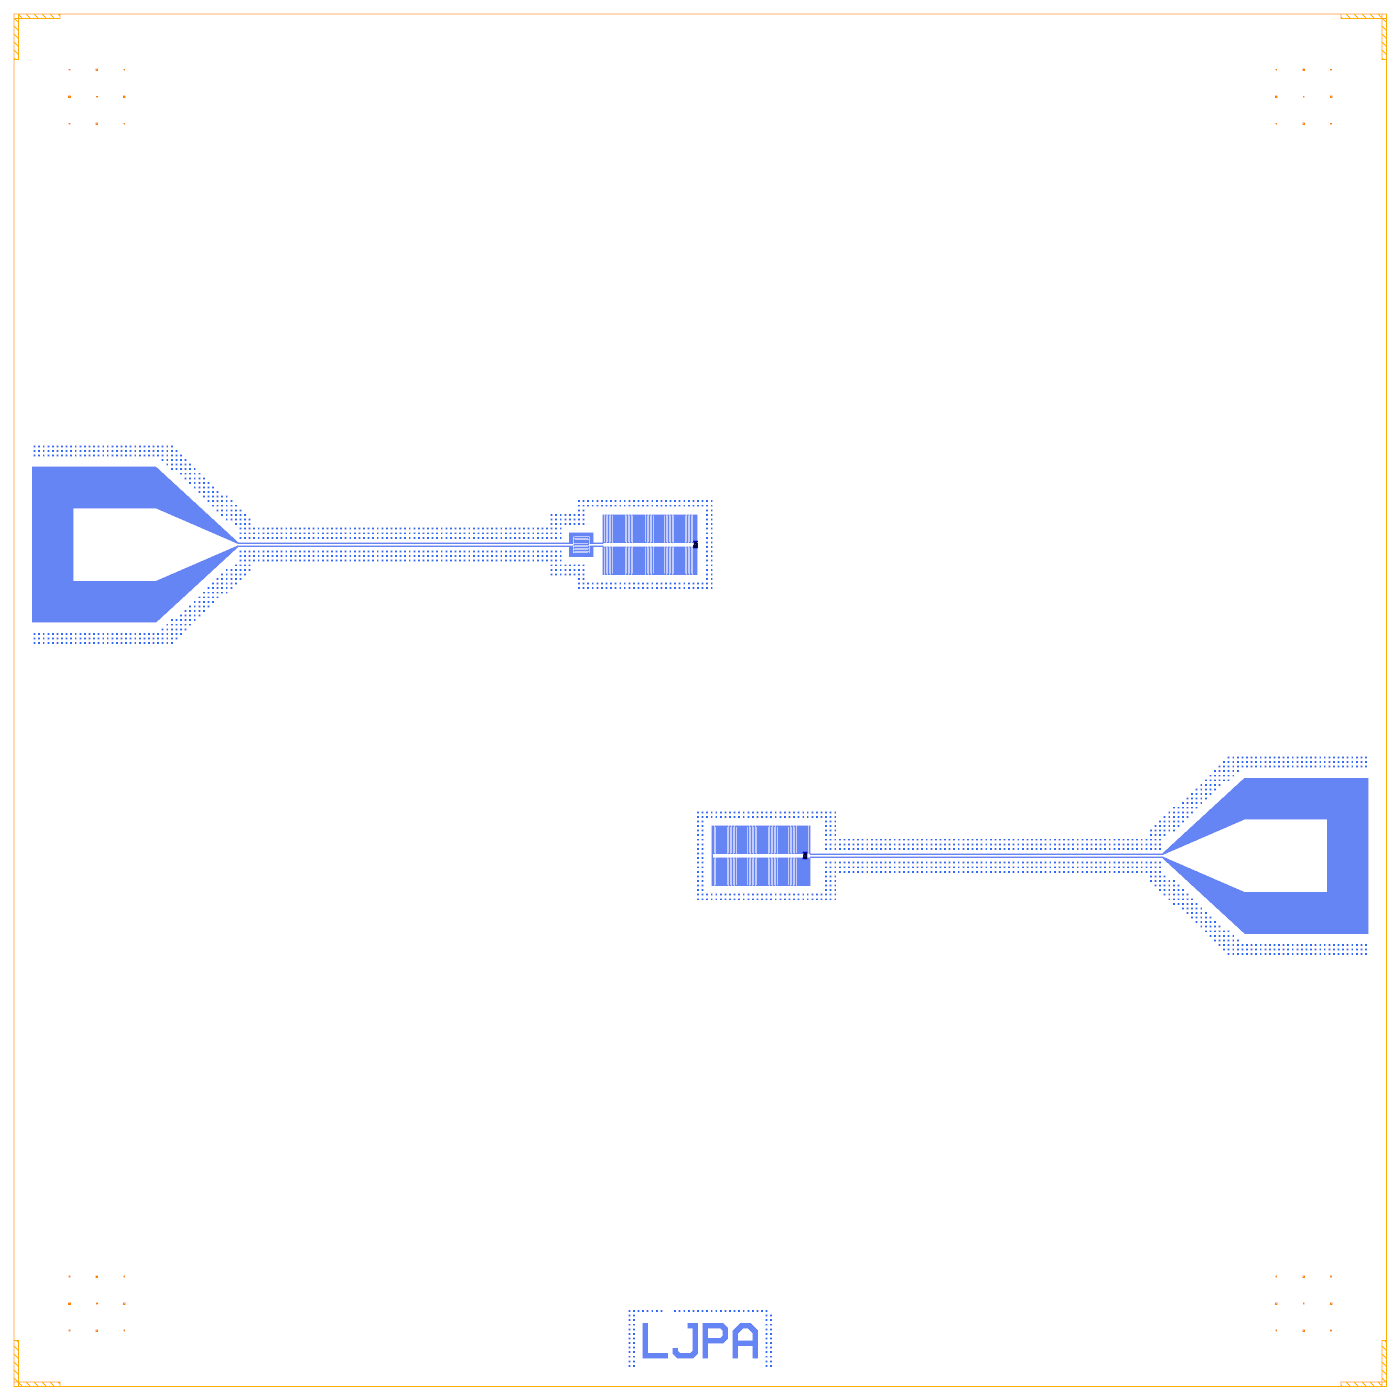

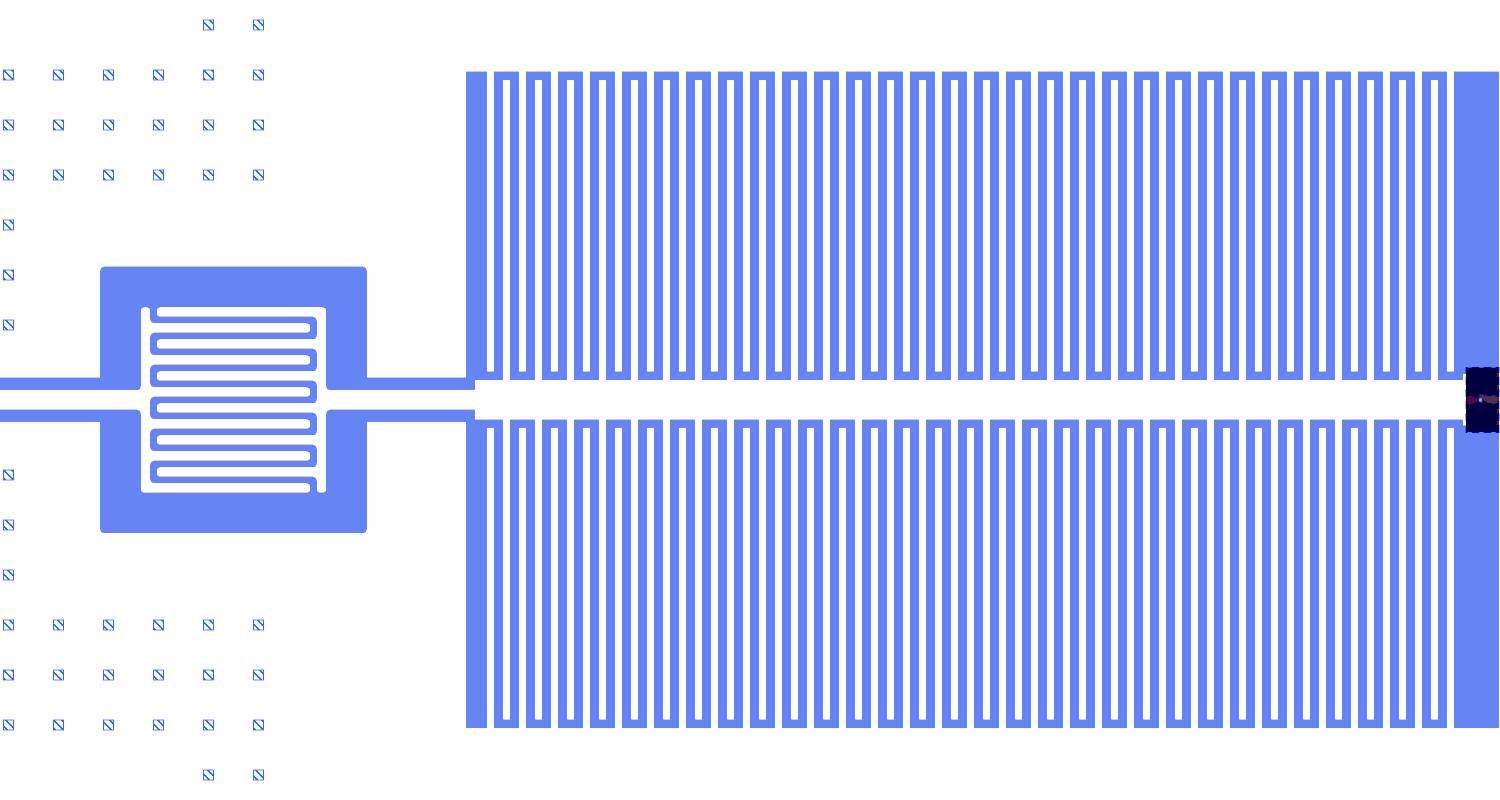

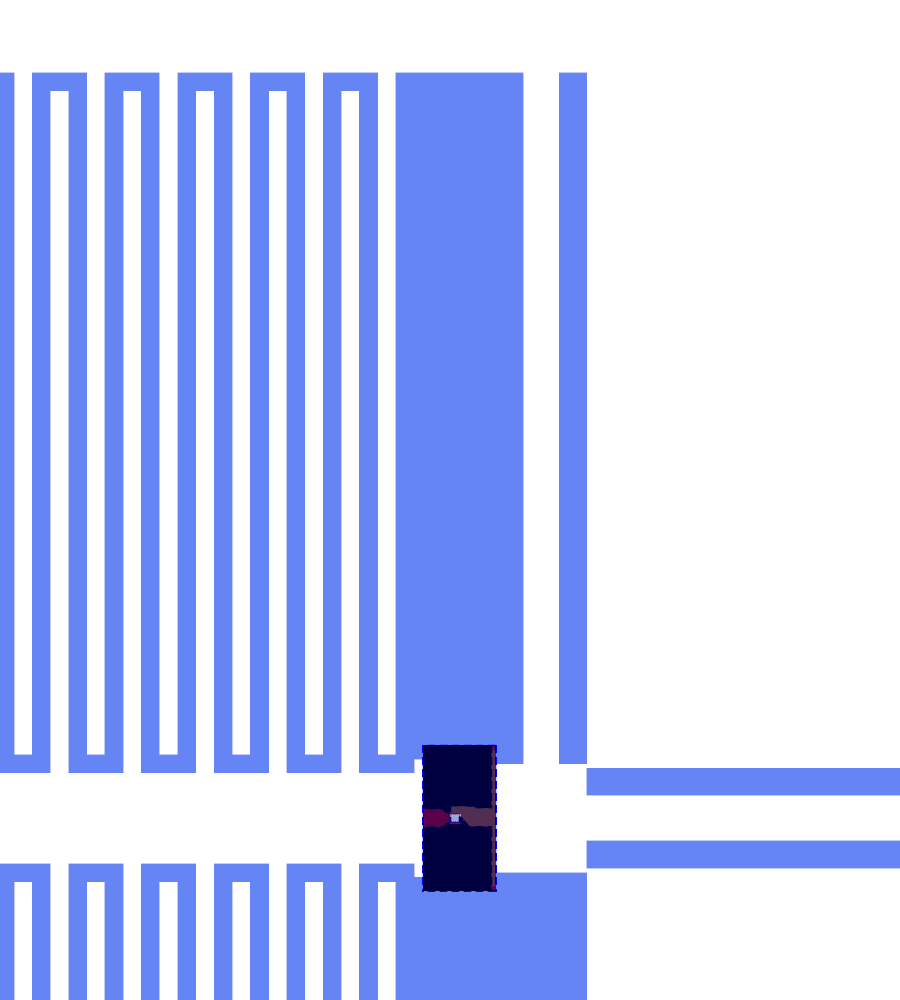

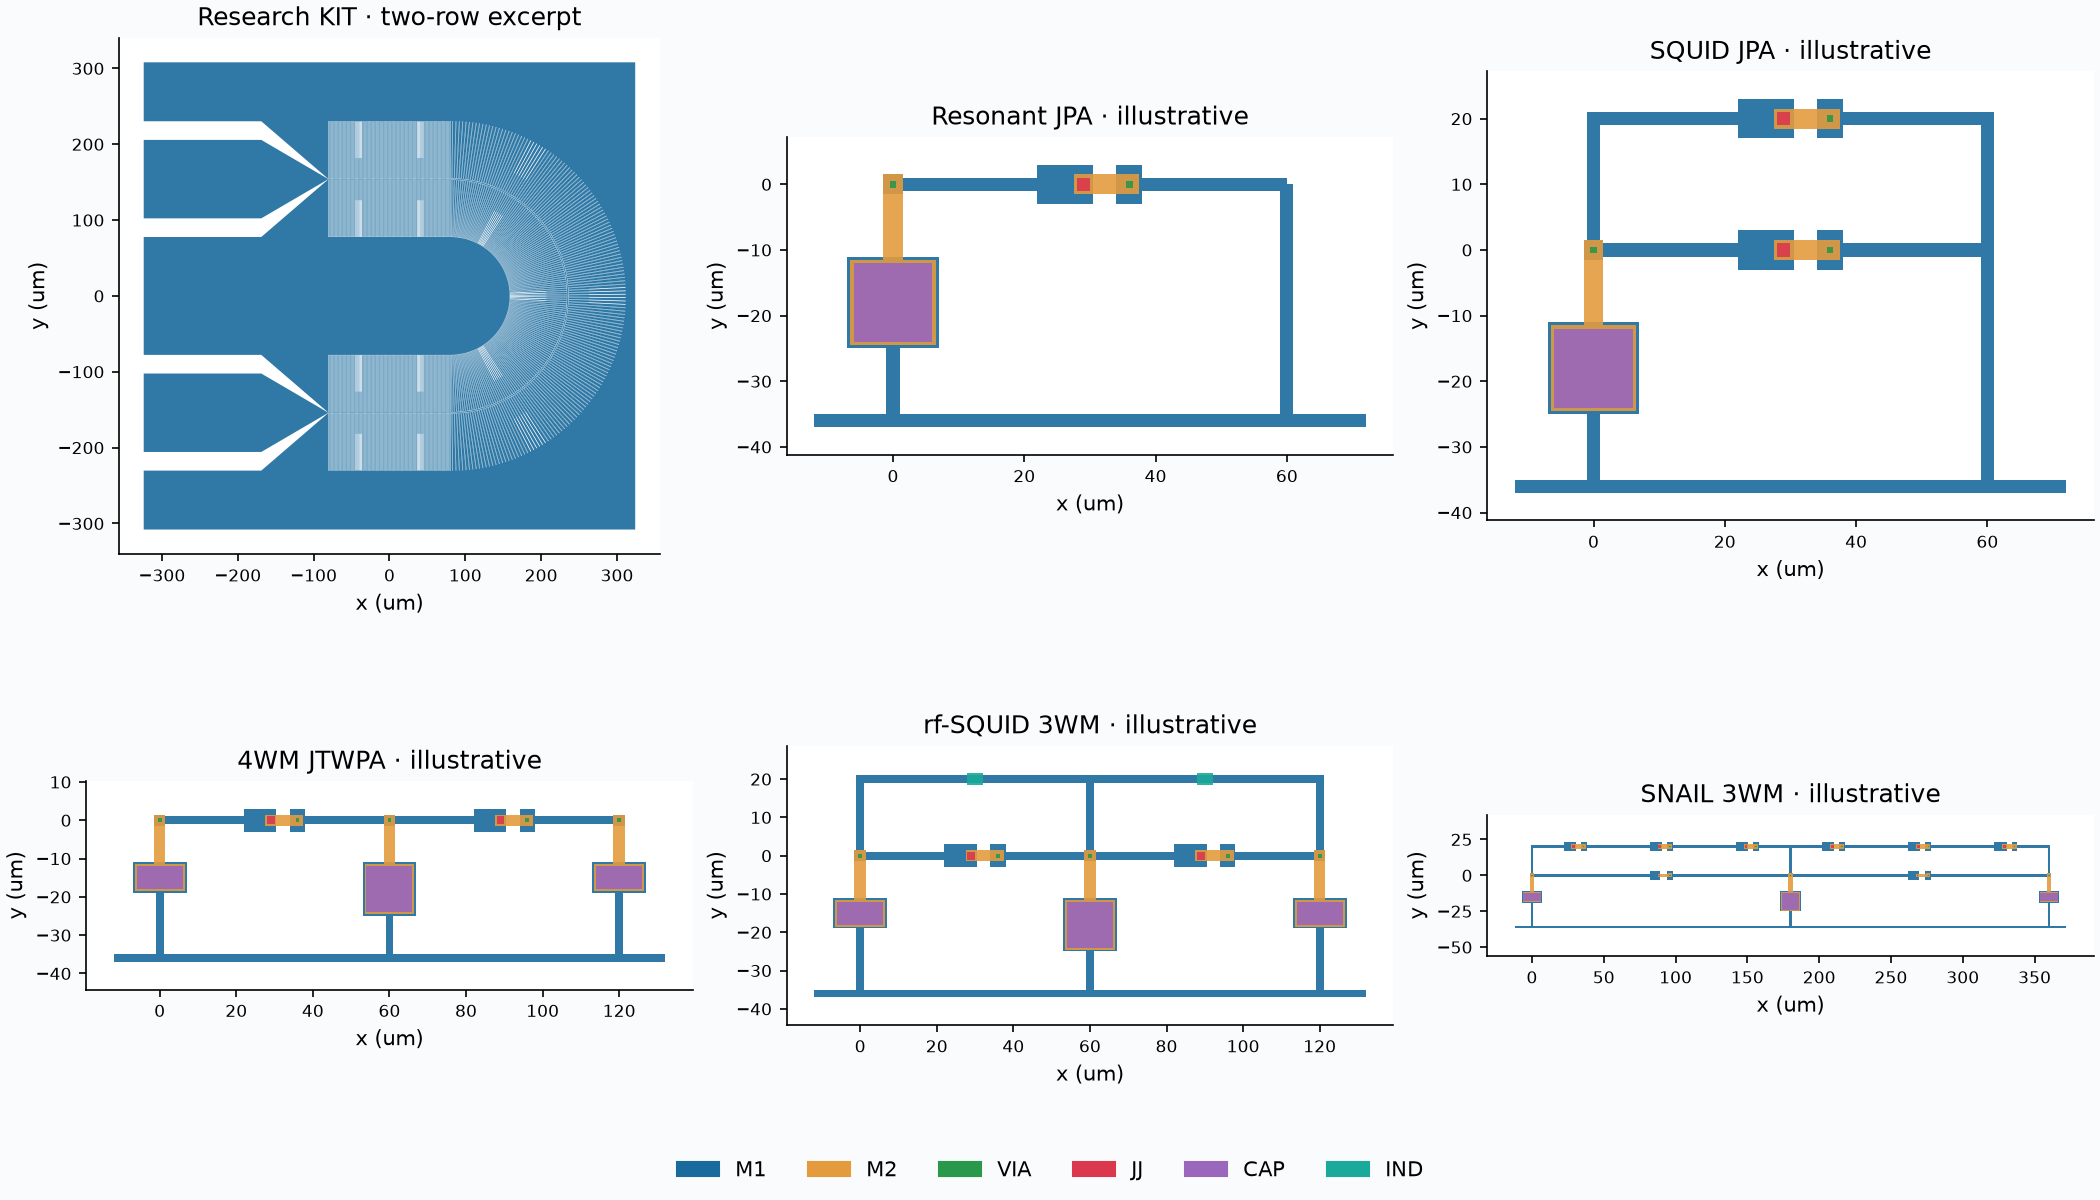

In [16]:
show_snapshot(d, OUT / "twpa_sim_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "twpa_sim_jpa_cap.png", box=(x - 50, y - 200, x + 700, y + 200), size=(1500, 800), width=600)
x, y = port_xy(d, "JL.signal")
show_snapshot(d, OUT / "twpa_sim_jpa_tap.png", box=(x - 130, y - 40, x - 30, y + 180), size=(900, 1000), width=400)
ref = ROOT / "build/external/twpa-sim/docs/assets/layout-families.png"
if ref.exists():
    display(Image(filename=str(ref), width=600))

## 14 · Summary
* **Matches the source:** one junction shunted by a capacitor to ground, one-port reflection amplifier, a
  capacitive and an inductive coupling variant.
* **Differs:** planar IDC instead of the MIM capacitor (the PDK has no MIM layer); the PDK trilayer junction
  (0.65 µA) instead of twpa-sim's illustrative 20 µA, so the shunt C is ≈ 0.9 pF for a ≈ 7 GHz mode (twpa-sim's
  values give ≈ 63 GHz); the inductive coupling is a galvanic tap (analytic L) instead of a mutual-inductance pickup
  loop.
* **PDK design warnings:** `pdk_rn` on `JC` and `JL` (R_n ≈ 3.4 kΩ).
* **Not modelled:** higher-order Kerr terms and pump depletion; the IDC's self-resonance (fingers 150 µm ≪ λ).